# Module 08: Initialization, Regularization, Normalization, and Stabilization

This notebook teaches **Initialization, Regularization, Normalization, and Stabilization** from basic intuition to practical deep-learning use.

Main coverage: Xavier, He initialization, dropout, weight decay, augmentation, batch norm, layer norm, residual connections, schedules, stability.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10
rng = np.random.default_rng(42)


## Module Outline

* **Step 1: Why initialization matters**
* **Step 2: Xavier initialization**
* **Step 3: He initialization**
* **Step 4: L1 L2 weight decay**
* **Step 5: Dropout**
* **Step 6: Data augmentation**
* **Step 7: Batch normalization**
* **Step 8: Layer normalization**
* **Step 9: Group and instance norm**
* **Step 10: Residual connections**
* **Step 11: Learning-rate schedules**
* **Step 12: Stabilization checklist**


## Step 2: Xavier initialization

**What is it?** Xavier initialization chooses weight scale to keep activation variance stable for tanh/sigmoid-like networks.

**Where it is used:** It is used when activations are roughly symmetric around zero.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Using Xavier as a default for ReLU networks where He initialization is usually more appropriate.


## Step 3: He initialization

**What is it?** He initialization uses variance suited for ReLU-like activations that zero out negative values.

**Where it is used:** It helps keep signals from shrinking through deep ReLU networks.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Using too small or too large initialization and blaming the optimizer.


## Step 4: L1 L2 weight decay

**What is it?** L1 encourages sparsity; L2/weight decay discourages large weights.

**Where it is used:** They regularize models and can reduce overfitting.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Confusing Adam L2 penalty with decoupled AdamW weight decay.


## Step 5: Dropout

**What is it?** Dropout randomly disables activations during training so the network cannot rely too heavily on individual units.

**Where it is used:** It is used mainly in dense layers and some attention blocks.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Forgetting dropout behaves differently in train and eval modes.


## Step 6: Data augmentation

**What is it?** Data augmentation creates label-preserving transformations of training examples.

**Where it is used:** It improves robustness and reduces memorization, especially in vision/audio/text.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Using transformations that change the correct label.


## Step 7: Batch normalization

**What is it?** BatchNorm normalizes activations using batch statistics during training and running statistics during inference.

**Where it is used:** It is common in CNNs and can stabilize optimization.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Using very small batches without understanding noisy batch statistics.


## Step 8: Layer normalization

**What is it?** LayerNorm normalizes features within each example instead of across the batch.

**Where it is used:** It is common in transformers and sequence models.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Replacing BatchNorm and LayerNorm blindly; they normalize different axes.


## Step 9: Group and instance norm

**What is it?** GroupNorm normalizes channel groups; InstanceNorm normalizes each channel per example.

**Where it is used:** They are useful in small-batch vision, style transfer, and image generation.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Choosing normalization without considering batch size and task.


## Step 10: Residual connections

**What is it?** Residual connections add a shortcut, often output = F(x)+x, so gradients and information can flow through deep networks.

**Where it is used:** They power ResNets and transformers.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Forgetting shape compatibility when adding shortcut tensors.


## Step 11: Learning-rate schedules

**What is it?** Schedules change LR over training to improve stability and convergence.

**Where it is used:** They are often paired with warmup and regularization.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Using an LR schedule copied from another dataset without matching total steps.


## Step 12: Stabilization checklist

**What is it?** A stabilization checklist verifies initialization, LR, normalization, gradients, loss scale, data scale, train/eval mode, and NaNs.

**Where it is used:** Use it when loss explodes, stalls, or behaves randomly.

**Why it matters:** This matters because it changes the correct model design, training behavior, evaluation method, or production reliability.

**Simple intuition:** Connect it to the concrete data shape, model operation, or metric used in this module, not just to the term name.

**Common mistake:** Adding random techniques without diagnosing the failure.


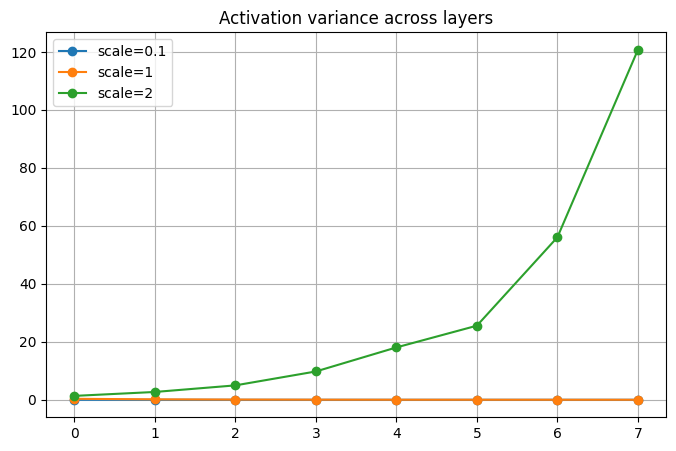

In [2]:
for scale in [.1,1,2]:
 a=rng.normal(size=(1000,100)); vars=[]
 for _ in range(8):
  W=rng.normal(0,scale/np.sqrt(100),size=(100,100)); a=np.maximum(0,a@W); vars.append(a.var())
 plt.plot(vars,marker='o',label=f'scale={scale}')
plt.legend(); plt.title('Activation variance across layers'); plt.show()


In [3]:
x=np.ones(20); mask=rng.binomial(1,.7,size=x.shape); display(pd.DataFrame({'before':x,'keep_mask':mask,'after':x*mask}))


,before,keep_mask,after
0,1.0,1,1.0
1,1.0,1,1.0
2,1.0,1,1.0
3,1.0,1,1.0
4,1.0,0,0.0
5,1.0,1,1.0
6,1.0,1,1.0
7,1.0,0,0.0
8,1.0,1,1.0
9,1.0,1,1.0


## Research-Backed Coverage Expansion: Initialization, Regularization, Normalization, and Stabilization

This expansion fills concepts commonly covered in deep-learning texts and courses such as the Deep Learning book, CS231n/CS224n, and Dive into Deep Learning. Each concept is written for learning flow: definition, where it is used, why it matters, and common mistakes.


### Fan-In and Fan-Out

**Definition:** Fan-in is number of inputs to a layer; fan-out is number of outputs.

**Where it is used:** Xavier/Glorot and He initialization.

**Why it matters:** They control variance of activations and gradients.

**Common mistake:** Using the same random scale for every layer.


### Activation Variance Propagation

**Definition:** How signal variance changes as it moves through layers.

**Where it is used:** Deep network initialization.

**Why it matters:** Exploding or shrinking activations make training unstable.

**Common mistake:** Checking only loss and not activation statistics.


### Gradient Variance Propagation

**Definition:** How gradient scale changes moving backward.

**Where it is used:** Deep networks and initialization.

**Why it matters:** Bad gradient scale causes vanishing/exploding gradients.

**Common mistake:** Thinking initialization affects only forward activations.


### Weight Decay vs L2 Penalty

**Definition:** Weight decay shrinks weights during updates; L2 adds squared weights to loss, with differences in adaptive optimizers.

**Where it is used:** Regularization and AdamW.

**Why it matters:** It helps control capacity and improve generalization.

**Common mistake:** Assuming Adam L2 is always the same as AdamW.


### Dropout Train vs Eval Mode

**Definition:** Dropout randomly drops units during training and is disabled or rescaled during evaluation.

**Where it is used:** MLPs, CNN heads, some older architectures.

**Why it matters:** Forgetting eval mode changes predictions.

**Common mistake:** Evaluating with dropout still active unintentionally.


### BatchNorm Running Statistics

**Definition:** BatchNorm keeps moving averages for inference.

**Where it is used:** CNNs and some MLPs.

**Why it matters:** Inference uses stored statistics, not current batch statistics.

**Common mistake:** Using tiny batches and expecting stable BatchNorm.


### LayerNorm in Transformers

**Definition:** LayerNorm normalizes per example across features.

**Where it is used:** Transformers and sequence models.

**Why it matters:** It works well when batch size or sequence length varies.

**Common mistake:** Replacing LayerNorm with BatchNorm blindly in transformers.


### Pre-Norm vs Post-Norm

**Definition:** LayerNorm can appear before or after sublayers in residual blocks.

**Where it is used:** Transformer stability.

**Why it matters:** Pre-norm often improves gradient flow in deep transformers.

**Common mistake:** Thinking all transformer blocks place normalization the same way.


### Residual Scaling

**Definition:** Scaling residual branches to control signal magnitude.

**Where it is used:** Very deep residual networks and transformers.

**Why it matters:** It prevents residual paths from growing too large.

**Common mistake:** Adding many residual branches without scale control.


### Stochastic Depth

**Definition:** Randomly skipping residual blocks during training.

**Where it is used:** Deep CNNs and vision transformers.

**Why it matters:** It regularizes very deep models.

**Common mistake:** Using it in small shallow models where it only hurts.


### Label Smoothing as Regularization

**Definition:** Softening hard labels to reduce overconfidence.

**Where it is used:** Classification models.

**Why it matters:** Can improve generalization and calibration.

**Common mistake:** Using it when exact probabilities are critical without checking calibration.


### Data Augmentation Strength

**Definition:** How strongly inputs are modified during training.

**Where it is used:** Vision, audio, text, and tabular robustness.

**Why it matters:** Too weak has little effect; too strong changes labels.

**Common mistake:** Applying augmentation that changes the true label.


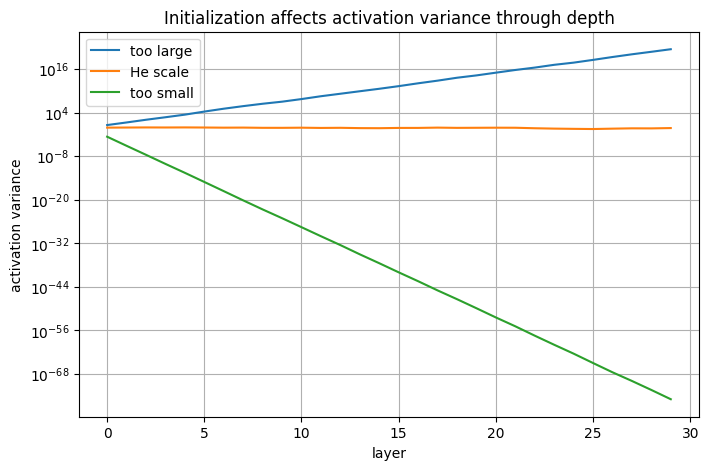

In [4]:
import numpy as np, matplotlib.pyplot as plt
rng = np.random.default_rng(0)
width, depth, samples = 256, 30, 512
X = rng.normal(size=(samples, width))
for scale, label in [(0.2, 'too large'), (np.sqrt(2/width), 'He scale'), (0.005, 'too small')]:
    A = X.copy(); variances = []
    for _ in range(depth):
        W = rng.normal(scale=scale, size=(width, width))
        A = np.maximum(0, A @ W)
        variances.append(A.var())
    plt.plot(variances, label=label)
plt.yscale('log')
plt.title('Initialization affects activation variance through depth')
plt.xlabel('layer'); plt.ylabel('activation variance'); plt.legend();


## Algorithm and Dataset Expansion: Stabilization Algorithms

This section connects the concepts to algorithms and datasets. For each module, the learner should understand what data shape is appropriate, which algorithm family fits the data, what metric to read, and what failure pattern to check.


### Stabilization Technique Map

| Technique | Algorithmic behavior | Use when | Risk |
|---|---|---|---|
| Xavier init | preserves variance for tanh-like activations | tanh/sigmoid historical nets | not ideal for ReLU |
| He init | preserves variance for ReLU-like activations | ReLU/GELU MLP/CNN | still can fail with poor LR |
| Weight decay | shrinks weights | overfitting or large weights | too much underfits |
| Dropout | randomly removes activations during training | dense layers and limited data | often less used inside modern transformer blocks |
| BatchNorm | normalizes batch activations | CNNs with decent batch size | train/eval mismatch |
| LayerNorm | normalizes features per example | transformers/RNNs | not same as BatchNorm |
| Residual connection | adds shortcut path | deep networks | shape must match |
| Gradient clipping | caps update signal | RNN/RL/unstable training | can hide deeper issues |


### Dataset Explanation

Use a **small image dataset or tabular classification dataset** to show regularization because overfitting is visible. Use a deliberately small training subset so the difference between train loss and validation loss appears.

The correct explanation is: regularization is not added because the model is bad. It is added because the model has enough capacity to memorize patterns that do not generalize.


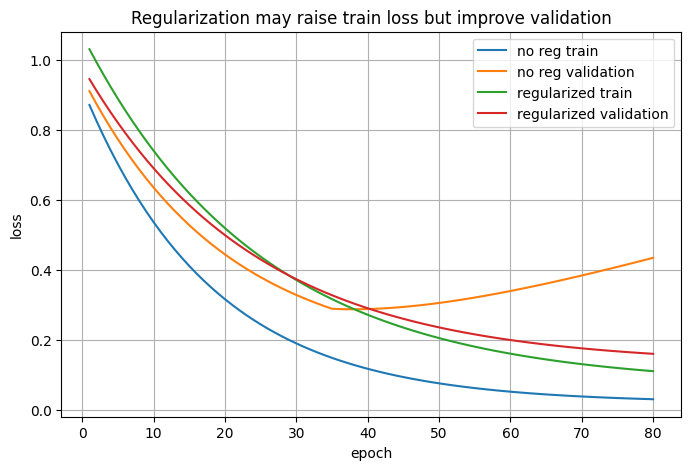

In [5]:
import numpy as np, matplotlib.pyplot as plt
epochs=np.arange(1,81)
no_reg_train=.9*np.exp(-epochs/18)+.02
no_reg_val=.8*np.exp(-epochs/20)+.15+.006*np.maximum(epochs-35,0)
reg_train=1.0*np.exp(-epochs/25)+.07
reg_val=.85*np.exp(-epochs/24)+.13
plt.plot(epochs,no_reg_train,label='no reg train')
plt.plot(epochs,no_reg_val,label='no reg validation')
plt.plot(epochs,reg_train,label='regularized train')
plt.plot(epochs,reg_val,label='regularized validation')
plt.title('Regularization may raise train loss but improve validation')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend();


## Complete Concept and Algorithm Coverage: Module 08 — Initialization, Regularization, Normalization, Stabilization

This section is a fuller checklist for the module. It is written so the learner can see not only the main concept, but also related algorithms, variants, correct datasets, metrics, and common failure modes.


| Area | Concepts / algorithms | What the student must understand |
|---|---|---|
| Initialization | normal/uniform, Xavier/Glorot, He/Kaiming, LeCun, orthogonal, LSUV, Fixup | Initial weight scale controls activation and gradient flow. |
| Regularization penalties | L1, L2, decoupled weight decay, max-norm, spectral norm | Penalties control weights and model smoothness differently. |
| Drop methods | dropout, spatial dropout, DropBlock, stochastic depth, attention dropout | Different structures need different dropout styles. |
| Data augmentation | crop, flip, color jitter, RandAugment, AutoAugment, Cutout, MixUp, CutMix | Augmentation teaches invariances and reduces memorization. |
| Normalization layers | BatchNorm, LayerNorm, GroupNorm, InstanceNorm, RMSNorm, WeightNorm | Normalization choice depends on architecture and batch behavior. |
| Residual stabilization | skip connections, pre-activation ResNet, pre-norm transformer, residual scaling, ReZero | Short paths help gradients flow through deep networks. |
| Training stabilizers | gradient clipping, EMA, SWA, label smoothing, warmup, mixed precision loss scaling | These make training smoother or improve generalization. |
| Robustness methods | adversarial training, noise injection, test-time augmentation | Used when models must handle perturbations or distribution changes. |
| Diagnostics | activation histograms, gradient histograms, train/eval mode checks, BatchNorm statistics | Stabilization should be measured, not guessed. |
| Dataset choice | small image subset for overfitting, CIFAR-style data for augmentation, transformers for LayerNorm/RMSNorm | Choose datasets where stabilization effects are visible. |


### Correct learning flow

Teach initialization first because it affects whether training starts correctly. Then teach regularization because it affects generalization. Then normalization and residuals because they explain how modern deep networks remain trainable.


In [6]:
import pandas as pd
norms = pd.DataFrame({
    'normalization':['BatchNorm','LayerNorm','GroupNorm','InstanceNorm','RMSNorm'],
    'normalizes_over':['batch + spatial/features','features within one example','groups of channels','each channel per example','root mean square of features'],
    'common_use':['CNNs','Transformers/RNNs','small-batch vision','style/image generation','modern LLM blocks']
})
display(norms)


,normalization,normalizes_over,common_use
0,BatchNorm,batch + spatial/features,CNNs
1,LayerNorm,features within one example,Transformers/RNNs
2,GroupNorm,groups of channels,small-batch vision
3,InstanceNorm,each channel per example,style/image generation
4,RMSNorm,root mean square of features,modern LLM blocks


## Module 08 Summary

This module covered **Initialization, Regularization, Normalization, and Stabilization** from foundation to advanced orientation. Review each step until you can explain what it is, where it is used, why it matters, and how the code/visual connects to the idea.
